# TP3 – Ventanas y fenómenos de la FFT

Este cuaderno muestra, con señales simuladas, qué se ve en el espectro al cambiar la frecuencia de muestreo, el tamaño de la ventana y el tipo de ventana. Reproduce los fenómenos que se observaron en la placa con el ejemplo de señal interna y sirve de base para las conclusiones del informe.

El firmware usa solo la **ventana rectangular** (no multiplica las muestras por nada antes de la FFT). La comparación con otras ventanas se hace acá.

Contenido:

1. Resolución en frecuencia según N y Fs
2. Muestreo coherente: sin fuga
3. Fuga espectral
4. Efecto de la ventana: rectangular contra Hann
5. Aliasing
6. Piso de cálculo de la FFT en q15
7. Comparación con las capturas de la placa
8. Conclusiones

Para ejecutarlo hacen falta las dependencias de `TP3/tools/requirements.txt` y Jupyter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Colores de las series, siempre en este orden
AZUL, NARANJA, VERDE, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS = "#52514e"

plt.rcParams.update({
    "figure.figsize": (9, 3.6),
    "figure.dpi": 90,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.grid": True,
    "grid.color": "#e3e2dd",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelcolor": GRIS,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "lines.linewidth": 1.6,
    "legend.frameon": False,
})

AMPLITUD = 0.8   # la misma del generador de tono del ejemplo: 0,8 de la escala completa
PISO_DB = -100.0  # valor que el firmware le asigna a un bin que da exactamente 0

## Funciones auxiliares

- `tono()` genera las N muestras de un seno.
- `espectro_dbfs()` calcula el espectro con la misma escala que el firmware: **0 dBFS es un tono de amplitud máxima**, para cualquier N. Devuelve los bins 0 a N/2 − 1, igual que la trama de la placa.

Con una ventana distinta de la rectangular, el espectro se divide por la suma de la ventana para que un tono que cae justo en un bin siga marcando su amplitud real.

In [2]:
def tono(f, fs, n, amplitud=AMPLITUD, fase=0.0):
    # n muestras de un seno de frecuencia f (Hz) muestreado a fs (Hz)
    k = np.arange(n)
    return amplitud * np.sin(2 * np.pi * f * k / fs + fase)


def espectro_dbfs(x, ventana=None):
    # Frecuencias (ciclos por muestra) y magnitud en dBFS de los bins 0 a N/2 - 1
    n = len(x)
    w = np.ones(n) if ventana is None else ventana
    mag = np.abs(np.fft.rfft(x * w))[: n // 2] / (np.sum(w) / 2)
    mag[0] /= 2  # la continua no se reparte en dos mitades
    return np.maximum(20 * np.log10(np.maximum(mag, 1e-12)), PISO_DB)


def frecuencias(fs, n):
    return np.arange(n // 2) * fs / n


def pico(db, fs, n):
    # Bin de mayor magnitud (sin contar la continua), su frecuencia y su nivel
    k = 1 + int(np.argmax(db[1:]))
    return k, k * fs / n, db[k]


def graficar(ax, fs, n, db, color=AZUL, etiqueta=None, **kw):
    ax.plot(frecuencias(fs, n), db, color=color, label=etiqueta, **kw)
    ax.set_xlim(0, fs / 2)
    ax.set_ylim(PISO_DB - 5, 5)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("Magnitud (dBFS)")

## 1. Resolución en frecuencia según N y Fs

La FFT de N puntos reparte el rango de 0 a Fs en N bins. La separación entre bins es la **resolución en frecuencia**, y la duración de la ventana es su inversa:

$$\Delta f = \frac{F_s}{N} \qquad T = \frac{N}{F_s} = \frac{1}{\Delta f}$$

Para ver más detalle en frecuencia hay que mirar la señal durante más tiempo: subiendo N o bajando Fs.

In [3]:
FS = [8000, 16000, 22000, 44000, 48000]
NS = [512, 1024, 2048]

print(f"{'Fs':>8} |" + "".join(f"  Δf N={n:<5}" for n in NS) + " |" + "".join(f"   T N={n:<5}" for n in NS))
for fs in FS:
    df = "".join(f"{fs / n:9.1f} Hz" for n in NS)
    t = "".join(f"{1000 * n / fs:9.1f} ms" for n in NS)
    print(f"{fs:>5} Hz |{df} |{t}")

      Fs |  Δf N=512    Δf N=1024   Δf N=2048  |   T N=512     T N=1024    T N=2048 
 8000 Hz |     15.6 Hz      7.8 Hz      3.9 Hz |     64.0 ms    128.0 ms    256.0 ms
16000 Hz |     31.2 Hz     15.6 Hz      7.8 Hz |     32.0 ms     64.0 ms    128.0 ms
22000 Hz |     43.0 Hz     21.5 Hz     10.7 Hz |     23.3 ms     46.5 ms     93.1 ms
44000 Hz |     85.9 Hz     43.0 Hz     21.5 Hz |     11.6 ms     23.3 ms     46.5 ms
48000 Hz |     93.8 Hz     46.9 Hz     23.4 Hz |     10.7 ms     21.3 ms     42.7 ms


**Dos tonos cercanos.** Dos senos de 1000 Hz y 1020 Hz (separados 20 Hz) a Fs = 8 kHz. Con N = 512 la resolución es de 15,6 Hz y los dos tonos se funden en un solo pico ancho. Con N = 2048 la resolución es de 3,9 Hz y se ven separados.

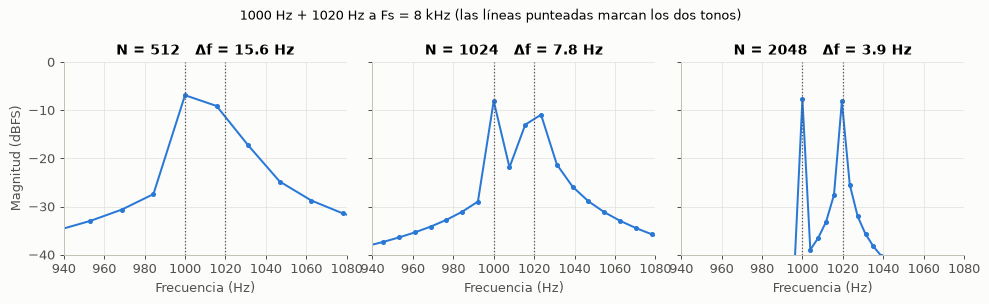

In [4]:
fs = 8000
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, n in zip(ejes, NS):
    x = tono(1000, fs, n, 0.4) + tono(1020, fs, n, 0.4)
    graficar(ax, fs, n, espectro_dbfs(x), marker="o", markersize=3)
    ax.set_xlim(940, 1080)
    ax.set_ylim(-40, 0)
    ax.set_title(f"N = {n}   Δf = {fs / n:.1f} Hz")
    for f in (1000, 1020):
        ax.axvline(f, color=GRIS, linestyle=":", linewidth=1)
ejes[1].set_ylabel(""); ejes[2].set_ylabel("")
fig.suptitle("1000 Hz + 1020 Hz a Fs = 8 kHz (las líneas punteadas marcan los dos tonos)", fontsize=10)
fig.tight_layout()

## 2. Muestreo coherente: sin fuga

Si la ventana contiene un **número entero de ciclos** del tono, el tono cae justo en un bin: toda su energía queda en ese bin y los demás quedan en cero. Eso pasa cuando $f / \Delta f$ es entero.

Con 1000 Hz a 8 kHz: $1000 / 15{,}625 = 64$ con N = 512 y $1000 / 7{,}8125 = 128$ con N = 1024.

El nivel del pico es $20 \log_{10} 0{,}8 = -1{,}94$ dBFS, porque el tono tiene amplitud 0,8.

N = 512: 1000 Hz / Δf = 64.00 -> bin 64, -1.94 dBFS; el resto de los bins, como mucho -100 dB
N = 1024: 1000 Hz / Δf = 128.00 -> bin 128, -1.94 dBFS; el resto de los bins, como mucho -100 dB


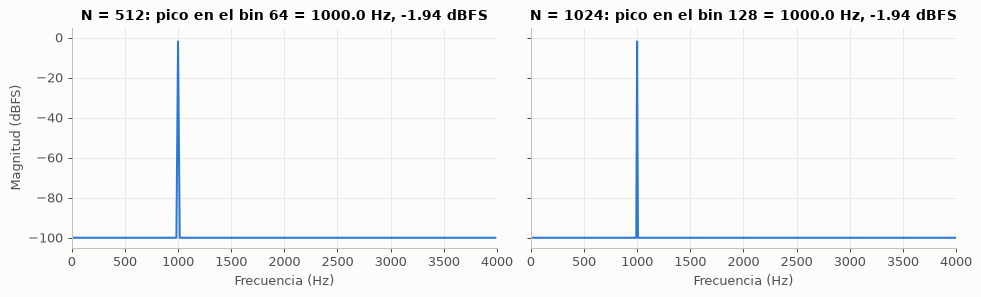

In [5]:
fs = 8000
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, n in zip(ejes, (512, 1024)):
    db = espectro_dbfs(tono(1000, fs, n))
    k, f, nivel = pico(db, fs, n)
    graficar(ax, fs, n, db)
    ax.set_title(f"N = {n}: pico en el bin {k} = {f:.1f} Hz, {nivel:.2f} dBFS")
    print(f"N = {n}: 1000 Hz / Δf = {1000 * n / fs:.2f} -> bin {k}, {nivel:.2f} dBFS; "
          f"el resto de los bins, como mucho {np.max(np.delete(db, k)):.0f} dB")
ejes[1].set_ylabel("")
fig.tight_layout()

## 3. Fuga espectral

Si el tono **no** completa un número entero de ciclos, cae entre dos bins. La ventana corta el seno en un punto cualquiera y ese corte reparte la energía por todo el espectro: es la *fuga espectral* (spectral leakage).

El peor caso es caer justo a mitad de camino entre dos bins. Con N = 1024 a 8 kHz eso pasa con 1004 Hz: $1004 / 7{,}8125 = 128{,}5$. Son solo 4 Hz de diferencia con el caso anterior.

Además de la "pollera" alrededor del pico, el pico mismo baja: la energía se reparte entre los dos bins vecinos. Esa pérdida se llama *scalloping loss* y con ventana rectangular llega a 3,9 dB.

1004 Hz: pico en el bin 129 = 1007.8 Hz, -5.67 dBFS
Pérdida respecto del caso coherente: 3.73 dB
Fuga cerca de 0 Hz: -48 dB; cerca de Fs/2: -65 dB


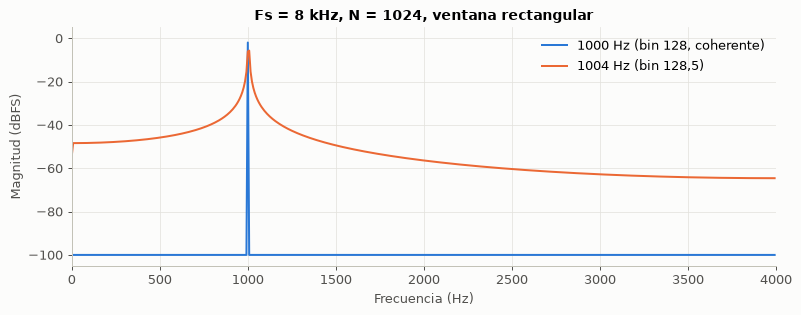

In [6]:
fs, n = 8000, 1024
db_1000 = espectro_dbfs(tono(1000, fs, n))
db_1004 = espectro_dbfs(tono(1004, fs, n))

fig, ax = plt.subplots()
graficar(ax, fs, n, db_1000, AZUL, "1000 Hz (bin 128, coherente)")
graficar(ax, fs, n, db_1004, NARANJA, "1004 Hz (bin 128,5)")
ax.set_title("Fs = 8 kHz, N = 1024, ventana rectangular")
ax.legend(loc="upper right")
fig.tight_layout()

k, f, nivel = pico(db_1004, fs, n)
print(f"1004 Hz: pico en el bin {k} = {f:.1f} Hz, {nivel:.2f} dBFS")
print(f"Pérdida respecto del caso coherente: {pico(db_1000, fs, n)[2] - nivel:.2f} dB")
print(f"Fuga cerca de 0 Hz: {db_1004[2]:.0f} dB; cerca de Fs/2: {db_1004[-2]:.0f} dB")

**La fuga parece ruido, pero no lo es.** Con 5000 Hz a 48 kHz y N = 512 el tono cae en el bin 53,33. Lejos del pico queda un piso cerca de −50 dB que se podría confundir con ruido. Con 3000 Hz (bin 32 exacto) ese piso desaparece por completo, con la misma Fs y el mismo N.

5000 Hz: 5000 / Δf = 53.33 -> pico en el bin 53 = 4968.8 Hz, -3.59 dBFS
Lejos del pico (de 12 kHz en adelante): entre -53 y -49 dB


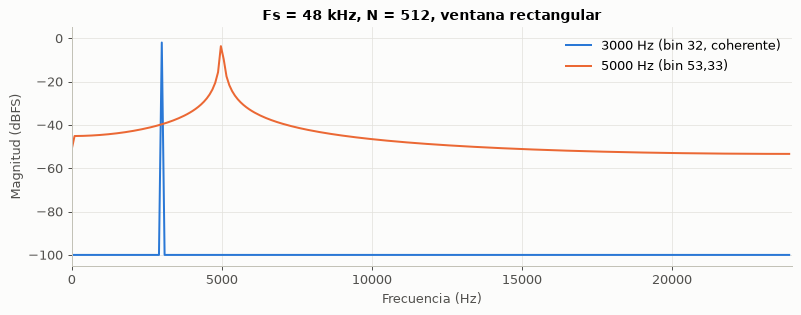

In [7]:
fs, n = 48000, 512
db_5000 = espectro_dbfs(tono(5000, fs, n))
db_3000 = espectro_dbfs(tono(3000, fs, n))

fig, ax = plt.subplots()
graficar(ax, fs, n, db_3000, AZUL, "3000 Hz (bin 32, coherente)")
graficar(ax, fs, n, db_5000, NARANJA, "5000 Hz (bin 53,33)")
ax.set_title("Fs = 48 kHz, N = 512, ventana rectangular")
ax.legend(loc="upper right")
fig.tight_layout()

k, f, nivel = pico(db_5000, fs, n)
lejos = db_5000[n // 4:]
print(f"5000 Hz: 5000 / Δf = {5000 * n / fs:.2f} -> pico en el bin {k} = {f:.1f} Hz, {nivel:.2f} dBFS")
print(f"Lejos del pico (de 12 kHz en adelante): entre {lejos.min():.0f} y {lejos.max():.0f} dB")

## 4. Efecto de la ventana: rectangular contra Hann

Una **ventana** es una curva por la que se multiplican las N muestras antes de la FFT. La de Hann vale cero en los dos extremos y uno en el centro, así que el seno ya no queda cortado de golpe en los bordes.

El cambio tiene un costo. En el espectro, cada tono queda dibujado con la forma de la transformada de la ventana:

- un **lóbulo principal**, cuyo ancho decide qué tan cerca pueden estar dos tonos para verse separados;
- **lóbulos laterales**, que son la fuga: qué tan altos son y qué tan rápido caen decide si un tono fuerte tapa a uno débil.

La ventana rectangular tiene el lóbulo principal más angosto, pero lóbulos laterales altos que caen despacio. Hann ensancha el lóbulo principal al doble a cambio de lóbulos laterales mucho más bajos.

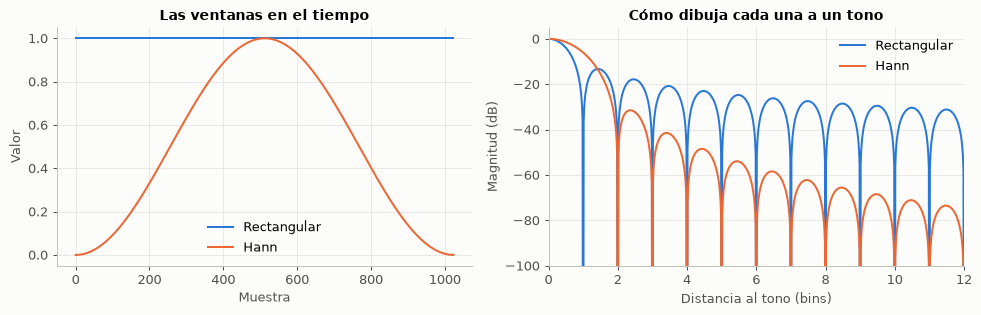

In [8]:
n = 1024
k = np.arange(n)
ventanas = {
    "Rectangular": np.ones(n),
    "Hann": 0.5 - 0.5 * np.cos(2 * np.pi * k / n),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
for (nombre, w), color in zip(ventanas.items(), (AZUL, NARANJA)):
    ax1.plot(k, w, color=color, label=nombre)
    # Transformada de la ventana, con mucho relleno de ceros para ver la forma de los lóbulos
    W = np.abs(np.fft.rfft(w, 64 * n))
    W_db = 20 * np.log10(np.maximum(W / W[0], 1e-12))
    ax2.plot(np.arange(len(W)) / 64, W_db, color=color, label=nombre)
ax1.set_title("Las ventanas en el tiempo")
ax1.set_xlabel("Muestra"); ax1.set_ylabel("Valor"); ax1.legend(loc="lower center")
ax2.set_title("Cómo dibuja cada una a un tono")
ax2.set_xlim(0, 12); ax2.set_ylim(-100, 5)
ax2.set_xlabel("Distancia al tono (bins)"); ax2.set_ylabel("Magnitud (dB)"); ax2.legend(loc="upper right")
fig.tight_layout()

**Los números de cada ventana**, medidos sobre su transformada. Se agregan Hamming y Blackman como referencia.

- *Ancho del lóbulo principal*: distancia entre los dos primeros ceros, en bins.
- *Lóbulo lateral más alto*: cuánto queda por debajo del pico la peor fuga.
- *Pérdida entre bins*: cuánto baja el pico cuando el tono cae a mitad de camino entre dos bins.

In [9]:
def medir_ventana(w, relleno=64):
    n = len(w)
    W = np.abs(np.fft.rfft(w, relleno * n))
    W_db = 20 * np.log10(np.maximum(W / W[0], 1e-15))
    # Primer mínimo local: fin del lóbulo principal
    i = 1
    while i < len(W) - 1 and not (W[i] < W[i - 1] and W[i] <= W[i + 1]):
        i += 1
    ancho = 2 * i / relleno
    lateral = W_db[i:].max()
    perdida = -W_db[relleno // 2]
    return ancho, lateral, perdida

todas = dict(ventanas)
todas["Hamming"] = 0.54 - 0.46 * np.cos(2 * np.pi * k / n)
todas["Blackman"] = 0.42 - 0.5 * np.cos(2 * np.pi * k / n) + 0.08 * np.cos(4 * np.pi * k / n)

print(f"{'Ventana':<12} {'Ancho lóbulo principal':>24} {'Lóbulo lateral más alto':>26} {'Pérdida entre bins':>20}")
for nombre, w in todas.items():
    ancho, lateral, perdida = medir_ventana(w)
    print(f"{nombre:<12} {ancho:>19.1f} bins {lateral:>23.1f} dB {perdida:>17.2f} dB")

Ventana        Ancho lóbulo principal    Lóbulo lateral más alto   Pérdida entre bins
Rectangular                  2.0 bins                   -13.3 dB              3.92 dB
Hann                         4.0 bins                   -31.5 dB              1.42 dB
Hamming                      4.0 bins                   -42.7 dB              1.75 dB
Blackman                     6.0 bins                   -58.1 dB              1.10 dB


### Tono que cae justo en un bin

Con muestreo coherente la ventana rectangular es la mejor: un solo bin. Hann reparte el tono en tres bins (el del centro y sus dos vecinos, 6 dB más abajo). Si el tono siempre cae en un bin, la ventana no ayuda.

1000 Hz, Rectangular: pico  -1.94 dBFS
1000 Hz, Hann       : pico  -1.94 dBFS
1004 Hz, Rectangular: pico  -5.67 dBFS
1004 Hz, Hann       : pico  -3.29 dBFS


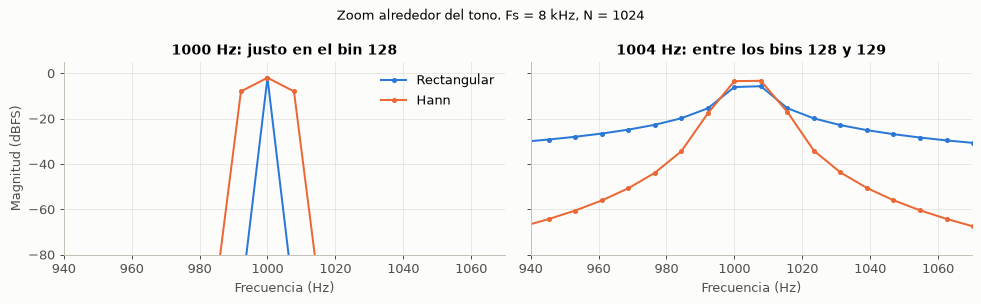

In [10]:
fs, n = 8000, 1024
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
casos = [(1000, "1000 Hz: justo en el bin 128"), (1004, "1004 Hz: entre los bins 128 y 129")]
for ax, (f, titulo) in zip(ejes, casos):
    x = tono(f, fs, n)
    for (nombre, w), color in zip(ventanas.items(), (AZUL, NARANJA)):
        db = espectro_dbfs(x, w)
        ax.plot(frecuencias(fs, n), db, color=color, marker="o", markersize=3, label=nombre)
        print(f"{f} Hz, {nombre:<11}: pico {pico(db, fs, n)[2]:6.2f} dBFS")
    ax.set_xlim(940, 1070); ax.set_ylim(-80, 5)
    ax.set_title(titulo); ax.set_xlabel("Frecuencia (Hz)")
ejes[0].set_ylabel("Magnitud (dBFS)"); ejes[0].legend(loc="upper right")
fig.suptitle("Zoom alrededor del tono. Fs = 8 kHz, N = 1024", fontsize=10)
fig.tight_layout()

### Tono que cae entre dos bins

Es el caso real: la frecuencia de una señal cualquiera no está sincronizada con el muestreo. Con la ventana rectangular la fuga llega a todo el espectro. Con Hann, a unos 20 bins del pico ya cayó por debajo de −80 dB. El pico además pierde menos: 1,4 dB en lugar de 3,9 dB.

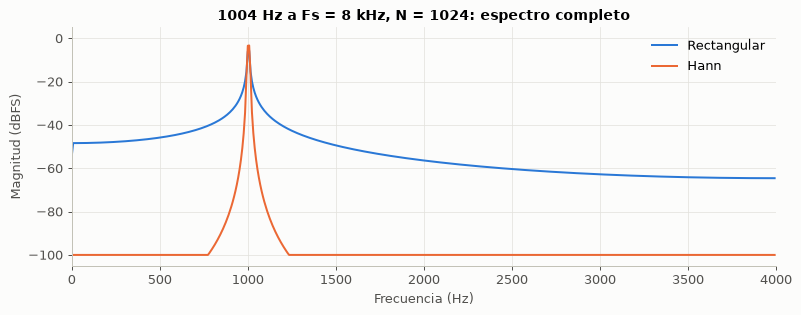

In [11]:
fs, n = 8000, 1024
x = tono(1004, fs, n)
fig, ax = plt.subplots()
for (nombre, w), color in zip(ventanas.items(), (AZUL, NARANJA)):
    graficar(ax, fs, n, espectro_dbfs(x, w), color, nombre)
ax.set_title("1004 Hz a Fs = 8 kHz, N = 1024: espectro completo")
ax.legend(loc="upper right")
fig.tight_layout()

### Un tono débil al lado de uno fuerte

Acá es donde la ventana cambia lo que se puede medir. Un tono de 1004 Hz con amplitud 0,8 y otro de 1500 Hz mil veces más chico (−60 dB respecto del primero).

Con la ventana rectangular, la fuga del tono fuerte a 1500 Hz está más alta que el tono débil: **no se ve**. Con Hann aparece claro.

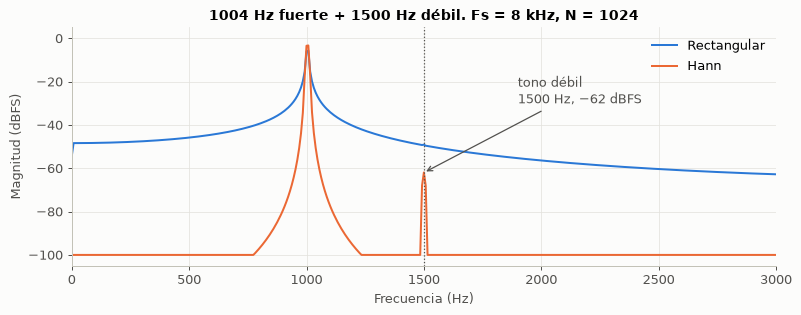

In [12]:
fs, n = 8000, 1024
x = tono(1004, fs, n) + tono(1500, fs, n, AMPLITUD / 1000)
fig, ax = plt.subplots()
for (nombre, w), color in zip(ventanas.items(), (AZUL, NARANJA)):
    graficar(ax, fs, n, espectro_dbfs(x, w), color, nombre)
ax.axvline(1500, color=GRIS, linestyle=":", linewidth=1)
ax.annotate("tono débil\n1500 Hz, −62 dBFS", xy=(1500, -62), xytext=(1900, -30), color=GRIS,
            arrowprops=dict(arrowstyle="->", color=GRIS))
ax.set_xlim(0, 3000)
ax.set_title("1004 Hz fuerte + 1500 Hz débil. Fs = 8 kHz, N = 1024")
ax.legend(loc="upper right")
fig.tight_layout()

## 5. Aliasing

Con una frecuencia de muestreo Fs solo se pueden representar frecuencias hasta Fs/2. Un tono por encima de Fs/2 produce **exactamente las mismas muestras** que otro por debajo, reflejado respecto de Fs/2. Después de muestrear no hay forma de distinguirlos.

Con 5000 Hz a Fs = 8 kHz, el tono aparece en $8000 - 5000 = 3000$ Hz.

Diferencia máxima entre las muestras de 5000 Hz y las de 3000 Hz invertido: 2.5e-13


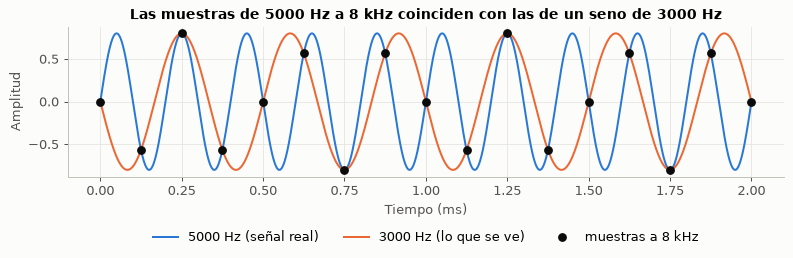

In [13]:
fs = 8000
t_fino = np.linspace(0, 2e-3, 2000)
k = np.arange(17)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t_fino * 1e3, AMPLITUD * np.sin(2 * np.pi * 5000 * t_fino), color=AZUL, label="5000 Hz (señal real)")
ax.plot(t_fino * 1e3, -AMPLITUD * np.sin(2 * np.pi * 3000 * t_fino), color=NARANJA, label="3000 Hz (lo que se ve)")
ax.plot(k / fs * 1e3, tono(5000, fs, len(k)), "o", color="#0b0b0b", markersize=6, label="muestras a 8 kHz")
ax.set_xlabel("Tiempo (ms)"); ax.set_ylabel("Amplitud")
ax.set_title("Las muestras de 5000 Hz a 8 kHz coinciden con las de un seno de 3000 Hz")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3)
fig.tight_layout()

diferencia = np.max(np.abs(tono(5000, fs, 512) + tono(3000, fs, 512)))
print(f"Diferencia máxima entre las muestras de 5000 Hz y las de 3000 Hz invertido: {diferencia:.1e}")

5000 Hz a Fs = 8000 Hz: pico en el bin 192 = 3000 Hz, -1.94 dBFS
5000 Hz a Fs = 16000 Hz: pico en el bin 160 = 5000 Hz, -1.94 dBFS


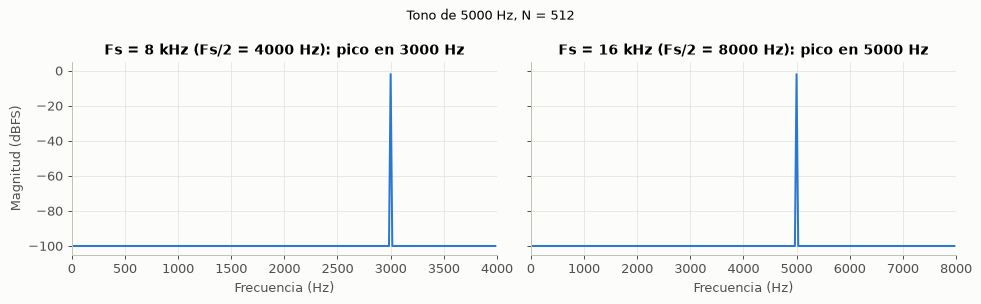

In [14]:
n = 512
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, fs in zip(ejes, (8000, 16000)):
    db = espectro_dbfs(tono(5000, fs, n))
    kp, f, nivel = pico(db, fs, n)
    graficar(ax, fs, n, db)
    ax.set_title(f"Fs = {fs // 1000} kHz (Fs/2 = {fs // 2} Hz): pico en {f:.0f} Hz")
    print(f"5000 Hz a Fs = {fs} Hz: pico en el bin {kp} = {f:.0f} Hz, {nivel:.2f} dBFS")
ejes[1].set_ylabel("")
fig.suptitle("Tono de 5000 Hz, N = 512", fontsize=10)
fig.tight_layout()

Subiendo Fs a 16 kHz, Fs/2 pasa a 8000 Hz y el tono de 5000 Hz aparece en su lugar.

En una adquisición real, el aliasing ocurre en el ADC. Para evitarlo hace falta un filtro analógico antes del ADC que quite lo que esté por encima de Fs/2; una vez muestreada la señal ya no se puede corregir.

## 6. Piso de cálculo de la FFT en q15

El firmware calcula la FFT con enteros de 16 bits (formato q15), no con números de punto flotante. Eso pone un límite a lo que puede mostrar:

- **El valor más chico distinto de cero.** La magnitud de cada bin sale como un entero. Un 1 en ese entero equivale a una amplitud de 1/8192, o sea $20 \log_{10}(1/8192) = -78{,}3$ dB. Dos valen −72,2 dB. Entre −78,3 dB y "nada" no hay valores intermedios.
- **Los bins que dan exactamente 0** no tienen logaritmo. El firmware les asigna −100 dB.
- **Error de redondeo.** Para que la cuenta no desborde, la FFT divide por 2 en cada etapa (por N en total). Cada división descarta el bit que sobra, y esos errores chicos se acumulan.

La celda siguiente hace una FFT con enteros que sigue esa misma idea: divide por 2 y descarta el resto en cada etapa. **Es un modelo simplificado, no una copia bit a bit de `arm_cfft_q15`**: sirve para ver de dónde sale el piso y de qué orden es, no para predecir el valor exacto de cada bin.

In [15]:
def fft_enteros(x_q15):
    # FFT de base 2 con enteros: en cada etapa divide por 2 y descarta el resto.
    # Devuelve la parte real e imaginaria de X[k] / N, en q15.
    n = len(x_q15)
    etapas = int(np.log2(n))
    indices = np.arange(n)
    invertidos = np.zeros(n, dtype=int)
    for b in range(etapas):
        invertidos |= ((indices >> b) & 1) << (etapas - 1 - b)
    re = x_q15[invertidos].astype(np.int64)
    im = np.zeros(n, dtype=np.int64)
    medio = 1
    while medio < n:
        ang = -np.pi * np.arange(medio) / medio
        wr = np.round(np.cos(ang) * 32767).astype(np.int64)
        wi = np.round(np.sin(ang) * 32767).astype(np.int64)
        for inicio in range(0, n, 2 * medio):
            a = slice(inicio, inicio + medio)
            b = slice(inicio + medio, inicio + 2 * medio)
            tr = (re[b] * wr - im[b] * wi) >> 15
            ti = (re[b] * wi + im[b] * wr) >> 15
            re[a], re[b] = (re[a] + tr) >> 1, (re[a] - tr) >> 1
            im[a], im[b] = (im[a] + ti) >> 1, (im[a] - ti) >> 1
        medio *= 2
    return re, im


def espectro_q15(x):
    # Espectro en dBFS como lo arma el firmware: magnitud entera, piso en -100 dB
    n = len(x)
    x_q15 = np.round(x * 32768).clip(-32768, 32767).astype(np.int64)
    re, im = fft_enteros(x_q15)
    mag = np.floor(np.sqrt(re[: n // 2] ** 2 + im[: n // 2] ** 2) / 2)  # entero: 8192 = amplitud 1
    amplitud = mag / 8192
    amplitud[0] = mag[0] / 16384
    return np.where(mag > 0, 20 * np.log10(np.maximum(amplitud, 1e-12)), PISO_DB)

print(f"1 en la magnitud entera = {20 * np.log10(1 / 8192):.1f} dB;  2 = {20 * np.log10(2 / 8192):.1f} dB;  "
      f"3 = {20 * np.log10(3 / 8192):.1f} dB")

1 en la magnitud entera = -78.3 dB;  2 = -72.2 dB;  3 = -68.7 dB


N = 512: pico -1.94 dBFS en 1000 Hz; 2 de 255 bins quedan por encima de -100 dB, el más alto en -78.3 dB
N = 1024: pico -1.94 dBFS en 1000 Hz; 1 de 511 bins quedan por encima de -100 dB, el más alto en -78.3 dB
N = 2048: pico -1.94 dBFS en 1000 Hz; 1 de 1023 bins quedan por encima de -100 dB, el más alto en -78.3 dB


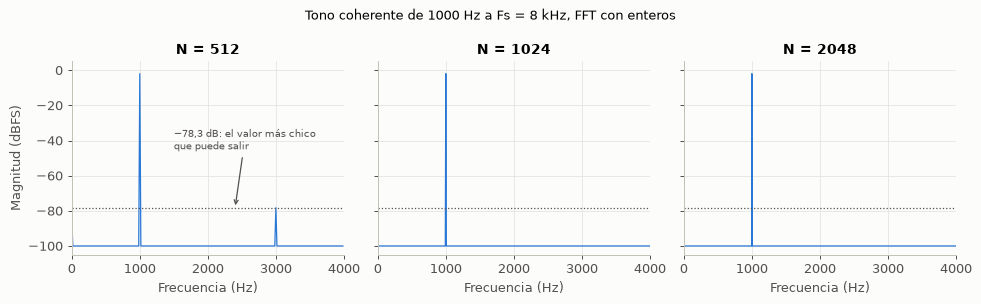

In [16]:
fs = 8000
rng = np.random.default_rng(3)
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, n in zip(ejes, NS):
    x = tono(1000, fs, n, fase=rng.uniform(0, 2 * np.pi))
    db = espectro_q15(x)
    graficar(ax, fs, n, db, linewidth=1.0)
    ax.axhline(-78.3, color=GRIS, linestyle=":", linewidth=1)
    kp, f, nivel = pico(db, fs, n)
    resto = np.delete(db, kp)
    ax.set_title(f"N = {n}")
    print(f"N = {n}: pico {nivel:.2f} dBFS en {f:.0f} Hz; {np.sum(resto > PISO_DB)} de {len(resto)} bins "
          f"quedan por encima de -100 dB, el más alto en {resto.max():.1f} dB")
ejes[0].annotate("−78,3 dB: el valor más chico\nque puede salir", xy=(2400, -78.3), xytext=(1500, -45),
                 color=GRIS, fontsize=8, arrowprops=dict(arrowstyle="->", color=GRIS))
ejes[1].set_ylabel(""); ejes[2].set_ylabel("")
fig.suptitle("Tono coherente de 1000 Hz a Fs = 8 kHz, FFT con enteros", fontsize=10)
fig.tight_layout()

Con números de punto flotante, este mismo tono da un solo bin y todo lo demás en cero (sección 2). Con enteros aparece algún bin suelto en −78,3 dB: es 1 unidad de la magnitud entera, producto del redondeo. Cae en la continua o en un múltiplo de la frecuencia del tono, porque con muestreo coherente el error de redondeo se repite igual en cada período.

Dos consecuencias para las mediciones en la placa:

- **Todo lo que esté por debajo de unos −78 dB no se puede ver**, sea señal o ruido.
- **Aumentar N no baja este piso.** Con más N hay más etapas y cada una agrega su redondeo. Para ganar rango haría falta una FFT de más precisión (enteros de 32 bits o punto flotante).

El mismo efecto con un tono que no cae en un bin: la fuga de la ventana rectangular queda muy por encima del piso de cálculo, así que es la fuga, y no la aritmética, lo que limita la medición en ese caso.

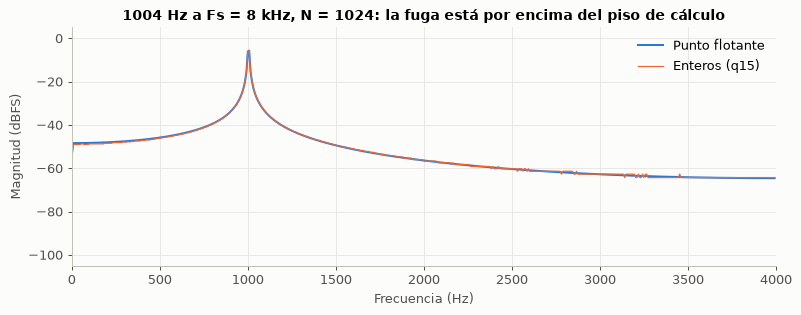

In [17]:
fs, n = 8000, 1024
x = tono(1004, fs, n)
fig, ax = plt.subplots()
graficar(ax, fs, n, espectro_dbfs(x), AZUL, "Punto flotante")
graficar(ax, fs, n, espectro_q15(x), NARANJA, "Enteros (q15)", linewidth=1.0)
ax.set_title("1004 Hz a Fs = 8 kHz, N = 1024: la fuga está por encima del piso de cálculo")
ax.legend(loc="upper right")
fig.tight_layout()

## 7. Comparación con las capturas de la placa

Las capturas se tomaron con el ejemplo de señal interna, usando la fuente sintética: un seno ideal en q15 escrito directo en la ventana, sin pasar por el DAC ni por el ADC. Están en la rama `tp3-ejemplo-senal-interna`, en `TP3/images/ejemplo_senal_interna/`, y se describen en `TP3/ejemplo_senal_interna.md` de esa rama.

La tabla compara lo que midió la placa con lo que calcula este cuaderno para la misma configuración.

In [18]:
# (tono, Fs, N, captura, bin de la placa, nivel de la placa en dBFS)
capturas = [
    (1000,  8000,  512, "sint_1000_fs8k_n512.png",        64, -1.9),
    (1000,  8000, 1024, "sint_1000_fs8k_n1024.png",      128, -1.9),
    (1004,  8000, 1024, "sint_1004_fs8k_n1024_fuga.png", 129, -5.7),
    (5000,  8000,  512, "sint_5000_fs8k_alias.png",      192, -1.9),
    (5000, 16000,  512, "sint_5000_fs16k.png",           160, -1.9),
    (5000, 48000,  512, "sint_5000_fs48k_fuga.png",       53, -3.6),
    (3000, 48000,  512, "sint_3000_fs48k_coherente.png",  32, -1.9),
]

print(f"{'Tono':>7} {'Fs':>6} {'N':>5} | {'Placa':^19} | {'Cuaderno':^19} | Captura")
print(f"{'':>7} {'':>6} {'':>5} | {'bin':>5} {'dBFS':>8}      | {'bin':>5} {'dBFS':>8}      |")
for f, fs, n, archivo, bin_placa, db_placa in capturas:
    kp, _, nivel = pico(espectro_dbfs(tono(f, fs, n)), fs, n)
    print(f"{f:>5} Hz {fs // 1000:>3} kHz {n:>5} | {bin_placa:>5} {db_placa:>8.1f}      | {kp:>5} {nivel:>8.2f}      | {archivo}")

   Tono     Fs     N |        Placa        |      Cuaderno       | Captura
                     |   bin     dBFS      |   bin     dBFS      |
 1000 Hz   8 kHz   512 |    64     -1.9      |    64    -1.94      | sint_1000_fs8k_n512.png
 1000 Hz   8 kHz  1024 |   128     -1.9      |   128    -1.94      | sint_1000_fs8k_n1024.png
 1004 Hz   8 kHz  1024 |   129     -5.7      |   129    -5.67      | sint_1004_fs8k_n1024_fuga.png
 5000 Hz   8 kHz   512 |   192     -1.9      |   192    -1.94      | sint_5000_fs8k_alias.png
 5000 Hz  16 kHz   512 |   160     -1.9      |   160    -1.94      | sint_5000_fs16k.png
 5000 Hz  48 kHz   512 |    53     -3.6      |    53    -3.59      | sint_5000_fs48k_fuga.png
 3000 Hz  48 kHz   512 |    32     -1.9      |    32    -1.94      | sint_3000_fs48k_coherente.png


El bin y el nivel del pico coinciden en todos los casos, dentro de la décima de dB con que se leyó cada captura. Eso incluye los dos casos con fuga (1004 Hz a 8 kHz y 5000 Hz a 48 kHz), donde el pico baja porque el tono cae entre dos bins.

Lo que este cuaderno no reproduce con exactitud es en qué bins aparecen los valores sueltos de −78 dB. En las capturas y en el modelo de la sección 6 caen en múltiplos de la frecuencia del tono y tienen el mismo nivel, pero no en los mismos bins: con el tono de 1000 Hz y N = 512, la placa lo mostró en 2000 Hz y el modelo en 3000 Hz. El modelo no copia bit a bit el redondeo de la biblioteca.

Las capturas con el lazo del DAC al ADC muestran además lo que aporta la parte analógica, que acá no se simula: un tercer armónico cerca de −57 dB, una componente de continua y ruido de 1 o 2 unidades repartido en todo el espectro.

## 8. Conclusiones

- **Resolución.** $\Delta f = F_s / N$. Para separar dos tonos cercanos hay que observar más tiempo: más N o menos Fs. El costo es una ventana más larga ($T = N / F_s$) y, con más N, más cálculo y una trama más grande.
- **Frecuencia de muestreo.** Fs fija el rango que se puede analizar (hasta Fs/2). Lo que esté por encima aparece reflejado y no se puede distinguir después de muestrear.
- **Muestreo coherente.** Si el tono completa un número entero de ciclos en la ventana, cae en un solo bin y no hay fuga. Es el caso ideal y sirve para comprobar la escala: un tono de amplitud 0,8 da −1,94 dBFS.
- **Fuga.** En general el tono cae entre dos bins. Con la ventana rectangular el pico baja hasta 3,9 dB y la energía se reparte por todo el espectro, con un piso que se puede confundir con ruido.
- **Ventana.** Hann baja la fuga lejos del pico en decenas de dB y reduce la pérdida del pico a 1,4 dB, a cambio de un pico el doble de ancho. Conviene cuando hay que ver tonos débiles cerca de uno fuerte; no aporta si el tono cae justo en un bin.
- **Aritmética en q15.** La FFT con enteros de 16 bits no puede mostrar nada por debajo de unos −78 dB, y ese límite no mejora al aumentar N.